In [1]:
import os

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)  

In [2]:
df = pd.read_csv("ONINE_FOOD_DELIVERY_ANALYSIS.csv")

# DATA INSPECTION

In [3]:
df.columns

Index(['Order_ID', 'Customer_ID', 'Customer_Age', 'Customer_Gender', 'City',
       'Area', 'Restaurant_ID', 'Restaurant_Name', 'Cuisine_Type',
       'Order_Date', 'Order_Time', 'Delivery_Time_Min', 'Distance_km',
       'Order_Value', 'Discount_Applied', 'Final_Amount', 'Payment_Mode',
       'Order_Status', 'Cancellation_Reason', 'Delivery_Partner_ID',
       'Delivery_Rating', 'Restaurant_Rating', 'Order_Day', 'Peak_Hour',
       'Profit_Margin'],
      dtype='str')

In [4]:
df.shape

(100000, 25)

In [5]:
df.head()

,Order_ID,Customer_ID,Customer_Age,Customer_Gender,City,Area,Restaurant_ID,Restaurant_Name,Cuisine_Type,Order_Date,...,Final_Amount,Payment_Mode,Order_Status,Cancellation_Reason,Delivery_Partner_ID,Delivery_Rating,Restaurant_Rating,Order_Day,Peak_Hour,Profit_Margin
0,ORD000001,CUST6948,19.0,Male,NaN,Central,RES936,Restaurant_29,Chinese,10/20/2024,...,NaN,UPI,Delivered,NaN,DP563,5.0,4.4,Weekend,True,0.13
1,ORD000002,CUST6515,NaN,Female,Chennai,North,RES689,Restaurant_419,Chinese,8/12/2024,...,4849.0,COD,Delivered,NaN,DP369,5.0,4.7,Weekday,True,0.48
2,ORD000003,CUST1765,NaN,Male,Delhi,NaN,RES723,Restaurant_244,Arabian,12/8/2024,...,737.0,Wallet,Delivered,NaN,DP580,4.0,4.9,Weekend,True,0.08
3,ORD000004,CUST2744,NaN,Male,Mumbai,Central,RES951,Restaurant_178,Chinese,10/8/2024,...,NaN,UPI,Cancelled,Late Delivery,DP155,2.0,3.4,Weekday,NaN,0.04
4,ORD000005,CUST4389,57.0,Female,Chennai,South,RES419,Restaurant_262,Chinese,2/4/2024,...,352.0,Card,Delivered,NaN,DP728,2.0,4.4,Weekend,False,0.12


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 25 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   Order_ID             100000 non-null  str    
 1   Customer_ID          100000 non-null  str    
 2   Customer_Age         49907 non-null   float64
 3   Customer_Gender      75144 non-null   str    
 4   City                 83274 non-null   str    
 5   Area                 83315 non-null   str    
 6   Restaurant_ID        100000 non-null  str    
 7   Restaurant_Name      100000 non-null  str    
 8   Cuisine_Type         83115 non-null   str    
 9   Order_Date           98986 non-null   str    
 10  Order_Time           98002 non-null   str    
 11  Delivery_Time_Min    66641 non-null   float64
 12  Distance_km          66530 non-null   float64
 13  Order_Value          66673 non-null   float64
 14  Discount_Applied     83285 non-null   float64
 15  Final_Amount         44303 no

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Customer_Age,49907.0,38.976516,12.372157,18.0,28.00,39.00,50.00,60.0
Delivery_Time_Min,66641.0,127.475923,90.805839,20.0,45.00,120.00,210.00,300.0
Distance_km,66530.0,16.449242,12.256742,1.0,5.47,9.97,27.43,40.0
Order_Value,66673.0,2081.830126,1553.628891,150.0,673.00,1197.00,3494.00,5000.0
Discount_Applied,83285.0,93.936243,108.209904,0.0,20.00,50.00,100.00,300.0
Final_Amount,44303.0,1961.101190,1557.354417,-150.0,559.00,1156.00,3375.00,4980.0
Delivery_Rating,83477.0,2.991531,1.414108,1.0,2.00,3.00,4.00,5.0
Restaurant_Rating,100000.0,4.249680,0.722554,3.0,3.60,4.20,4.90,5.5
Profit_Margin,100000.0,0.150362,0.201888,-0.2,-0.02,0.15,0.32,0.5


In [8]:
df.dtypes

Order_ID                   str
Customer_ID                str
Customer_Age           float64
Customer_Gender            str
City                       str
Area                       str
Restaurant_ID              str
Restaurant_Name            str
Cuisine_Type               str
Order_Date                 str
Order_Time                 str
Delivery_Time_Min      float64
Distance_km            float64
Order_Value            float64
Discount_Applied       float64
Final_Amount           float64
Payment_Mode               str
Order_Status               str
Cancellation_Reason        str
Delivery_Partner_ID        str
Delivery_Rating        float64
Restaurant_Rating      float64
Order_Day                  str
Peak_Hour               object
Profit_Margin          float64
dtype: object

In [9]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"], format="mixed", errors="coerce")

In [10]:
df["Order_Date"] = df["Order_Date"].dt.normalize()

In [11]:
for col in ["Order_ID", "Customer_ID", "Restaurant_ID", "Delivery_Partner_ID"]:
    df[col] = df[col].astype("str")


In [12]:
df["Peak_Hour"] = df["Peak_Hour"].map({True: "Peak", False: "Off-Peak"}).fillna("Unknown")


In [13]:
print(df["Peak_Hour"].value_counts(dropna=False))


Peak_Hour
Off-Peak    33585
Peak        33453
Unknown     32962
Name: count, dtype: int64


In [14]:
for col in ["Customer_Age", "Delivery_Time_Min", "Delivery_Rating"]:
    df[col] = df[col].round().astype("Int64")

In [15]:
df.dtypes

Order_ID                          str
Customer_ID                       str
Customer_Age                    Int64
Customer_Gender                   str
City                              str
Area                              str
Restaurant_ID                     str
Restaurant_Name                   str
Cuisine_Type                      str
Order_Date             datetime64[us]
Order_Time                        str
Delivery_Time_Min               Int64
Distance_km                   float64
Order_Value                   float64
Discount_Applied              float64
Final_Amount                  float64
Payment_Mode                      str
Order_Status                      str
Cancellation_Reason               str
Delivery_Partner_ID               str
Delivery_Rating                 Int64
Restaurant_Rating             float64
Order_Day                         str
Peak_Hour                         str
Profit_Margin                 float64
dtype: object

# DATA CLEANING

In [16]:
df.isnull().sum()

Order_ID                   0
Customer_ID                0
Customer_Age           50093
Customer_Gender        24856
City                   16726
Area                   16685
Restaurant_ID              0
Restaurant_Name            0
Cuisine_Type           16885
Order_Date              1014
Order_Time              1998
Delivery_Time_Min      33359
Distance_km            33470
Order_Value            33327
Discount_Applied       16715
Final_Amount           55697
Payment_Mode           19911
Order_Status               0
Cancellation_Reason    90969
Delivery_Partner_ID        0
Delivery_Rating        16523
Restaurant_Rating          0
Order_Day                  0
Peak_Hour                  0
Profit_Margin              0
dtype: int64

In [17]:
df.isnull().mean()*100

Order_ID                0.000
Customer_ID             0.000
Customer_Age           50.093
Customer_Gender        24.856
City                   16.726
Area                   16.685
Restaurant_ID           0.000
Restaurant_Name         0.000
Cuisine_Type           16.885
Order_Date              1.014
Order_Time              1.998
Delivery_Time_Min      33.359
Distance_km            33.470
Order_Value            33.327
Discount_Applied       16.715
Final_Amount           55.697
Payment_Mode           19.911
Order_Status            0.000
Cancellation_Reason    90.969
Delivery_Partner_ID     0.000
Delivery_Rating        16.523
Restaurant_Rating       0.000
Order_Day               0.000
Peak_Hour               0.000
Profit_Margin           0.000
dtype: float64

In [18]:
df.duplicated(subset=['Order_ID']).sum()

np.int64(0)

In [19]:
df.drop(columns=["Order_Time"], inplace=True)


In [20]:
for col in ["Customer_Gender", "City", "Area", "Cuisine_Type", "Payment_Mode"]:
    df[col] = df[col].fillna("Unknown")


In [21]:
df['Cancellation_Reason'].value_counts()

Cancellation_Reason
Late Delivery         3059
Customer Cancelled    2993
Restaurant Issue      2979
Name: count, dtype: int64

In [22]:
cancelled = df["Order_Status"] == "Cancelled"
delivered = df["Order_Status"] == "Delivered"
df.loc[cancelled, ["Delivery_Rating", "Delivery_Time_Min"]] = np.nan


In [23]:
df.loc[cancelled & df["Cancellation_Reason"].isna(), "Cancellation_Reason"] = "Not Specified"
df.loc[delivered & df["Cancellation_Reason"].isna(), "Cancellation_Reason"] = "Not Applicable"
df["Cancellation_Reason"].value_counts()

Cancellation_Reason
Not Applicable        84964
Not Specified          6005
Late Delivery          3059
Customer Cancelled     2993
Restaurant Issue       2979
Name: count, dtype: int64

In [24]:
df["Customer_Age"].describe()

count      49907.0
mean     38.976516
std      12.372157
min           18.0
25%           28.0
50%           39.0
75%           50.0
max           60.0
Name: Customer_Age, dtype: Float64

In [25]:
len(df[(df['Customer_Age']<=0)|(df['Customer_Age']>100)])

0

In [26]:
df['Customer_Age'].isnull().sum()

np.int64(50093)

In [27]:
df[(df['Customer_Age']>0)&(df['Customer_Age']<100)][['Customer_Age']].describe()

,Customer_Age
count,49907.0
mean,38.976516
std,12.372157
min,18.0
25%,28.0
50%,39.0
75%,50.0
max,60.0


<Axes: ylabel='Frequency'>

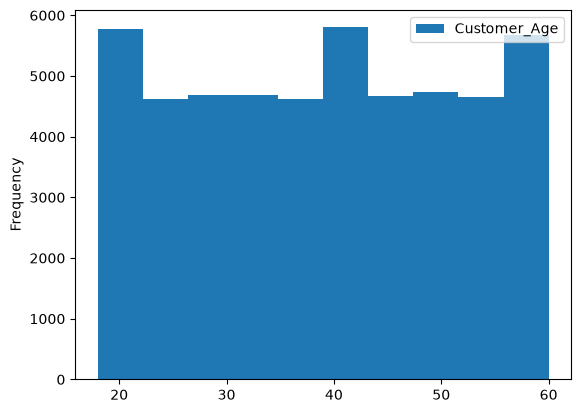

In [28]:
df[(df['Customer_Age']>0)&(df['Customer_Age']<100)][['Customer_Age']].plot(kind='hist')

In [29]:
Proportion=df[(df['Customer_Age']>0)&(df['Customer_Age']<100)][['Customer_Age']].value_counts(normalize=True)
Proportion

Customer_Age
27              0.025247
33              0.025047
49              0.024906
34              0.024205
23              0.024065
53              0.023965
46              0.023965
19              0.023904
56              0.023844
55              0.023744
40              0.023624
44              0.023584
29              0.023524
39              0.023504
48              0.023484
30              0.023363
42              0.023363
36              0.023343
51              0.023303
57              0.023283
38              0.023283
45              0.023263
18              0.023183
37              0.023163
21              0.023123
50              0.023083
25              0.023063
32              0.023003
26              0.022963
43              0.022963
35              0.022923
41              0.022782
54              0.022782
22              0.022762
47              0.022662
20              0.022662
52              0.022622
24              0.022502
59              0.022402
60          

In [30]:
Fill_index=df[(df['Customer_Age'].isnull())|(df['Customer_Age']<=0)|(df['Customer_Age']>100)]['Customer_Age'].index
Fill_index

Index([    1,     2,     3,     7,     8,     9,    10,    11,    12,    13,
       ...
       99985, 99986, 99990, 99991, 99994, 99995, 99996, 99997, 99998, 99999],
      dtype='int64', length=50093)

In [31]:
Proportion.index

MultiIndex([(27,),
            (33,),
            (49,),
            (34,),
            (23,),
            (53,),
            (46,),
            (19,),
            (56,),
            (55,),
            (40,),
            (44,),
            (29,),
            (39,),
            (48,),
            (30,),
            (42,),
            (36,),
            (51,),
            (57,),
            (38,),
            (45,),
            (18,),
            (37,),
            (21,),
            (50,),
            (25,),
            (32,),
            (26,),
            (43,),
            (35,),
            (41,),
            (54,),
            (22,),
            (47,),
            (20,),
            (52,),
            (24,),
            (59,),
            (60,),
            (58,),
            (28,),
            (31,)],
           names=['Customer_Age'])

In [32]:
Proportion.values

array([0.02524696, 0.02504659, 0.02490633, 0.02420502, 0.02406476,
       0.02396457, 0.02396457, 0.02390446, 0.02384435, 0.02374416,
       0.02362394, 0.02358387, 0.02352375, 0.02350372, 0.02348368,
       0.02336346, 0.02336346, 0.02334342, 0.02330334, 0.02328331,
       0.02328331, 0.02326327, 0.02318312, 0.02316308, 0.02312301,
       0.02308293, 0.0230629 , 0.02300279, 0.02296271, 0.02296271,
       0.02292264, 0.02278238, 0.02278238, 0.02276234, 0.02266215,
       0.02266215, 0.02262208, 0.02250185, 0.02240167, 0.02236159,
       0.02196085, 0.0217204 , 0.02149999])

In [33]:
df.loc[0:10, ["Customer_ID", "Customer_Age"]]

,Customer_ID,Customer_Age
0,CUST6948,19
1,CUST6515,<NA>
2,CUST1765,<NA>
3,CUST2744,<NA>
4,CUST4389,57
5,CUST3161,37
6,CUST2307,40
7,CUST5865,<NA>
8,CUST4356,<NA>
9,CUST2404,<NA>


In [34]:
Proportion = df['Customer_Age'].value_counts(normalize=True)

Fill_index = df.index[df['Customer_Age'].isna()]

df.loc[Fill_index, 'Customer_Age'] = np.random.choice(
    Proportion.index.to_numpy(),
    size=len(Fill_index),
    p=Proportion.values
)

In [35]:
print(df['Customer_Age'].dtype)
print(Proportion.index[:5])    
df['Customer_Age'] = pd.to_numeric(df['Customer_Age'], errors='coerce')

Int64
Index([27, 33, 49, 34, 23], dtype='Int64', name='Customer_Age')


In [36]:
df["Customer_Age"].isnull().sum()

np.int64(0)

<Axes: ylabel='Frequency'>

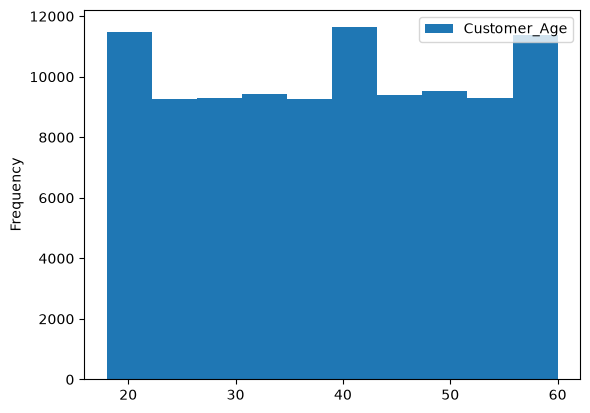

In [37]:
df[(df['Customer_Age']>0)&(df['Customer_Age']<100)][['Customer_Age']].plot(kind='hist')

In [38]:
df["Delivery_Rating"].isnull().sum()

np.int64(29084)

In [39]:
delivered = df["Order_Status"] == "Delivered"
rating_median = df.loc[delivered, "Delivery_Rating"].median()
df.loc[delivered, "Delivery_Rating"] = df.loc[delivered, "Delivery_Rating"].fillna(rating_median)

In [40]:
df["Delivery_Time_Min"] = pd.to_numeric(df["Delivery_Time_Min"], errors="coerce")
delivered = df["Order_Status"] == "Delivered"

In [41]:
df["Delivery_Time_Min"] = df["Delivery_Time_Min"].astype(float)

real_delivery_time = df["Delivery_Time_Min"].copy()

city_mean = df[delivered].groupby("City")["Delivery_Time_Min"].transform("mean")
df.loc[delivered, "Delivery_Time_Min"] = df.loc[delivered, "Delivery_Time_Min"].fillna(city_mean)

In [42]:
df["Distance_km"] = df.groupby("City")["Distance_km"].transform(lambda s: s.fillna(s.mean())).round(2)

In [43]:
cancelled = df["Order_Status"] == "Cancelled"
df.loc[cancelled, ["Delivery_Time_Min", "Delivery_Rating"]] = np.nan


In [44]:
df["Delivery_Time_Min"] = df["Delivery_Time_Min"].round().astype("Int64")
df["Delivery_Rating"] = df["Delivery_Rating"].round().astype("Int64")

## Missing Delivery Time and Rating

- **Cancelled orders:** these were never delivered, so they have no delivery time or rating. I kept them empty while analysing, so they don't spoil the charts.

In [45]:
df["Discount_Applied"].value_counts()

Discount_Applied
100.0    16776
50.0     16690
0.0      16650
300.0    16600
20.0     16569
Name: count, dtype: int64

In [46]:
df["Discount_Applied"] = df["Discount_Applied"].fillna(0)

df["Discount_Applied"] = df[["Discount_Applied", "Order_Value"]].min(axis=1)

In [47]:
print("Missing Discount:",
      df["Discount_Applied"].isnull().sum())

print("Negative Discount:",
      (df["Discount_Applied"] < 0).sum())

print("Discount > Order Value:",
      (df["Discount_Applied"] > df["Order_Value"]).sum())

Missing Discount: 0
Negative Discount: 0
Discount > Order Value: 0


In [48]:
df[["Order_Value", "Discount_Applied"]].head()

,Order_Value,Discount_Applied
0,NaN,0.0
1,4869.0,20.0
2,757.0,20.0
3,NaN,0.0
4,372.0,20.0


In [49]:
df[["Order_Value", "Discount_Applied", "Final_Amount"]].describe()

,Order_Value,Discount_Applied,Final_Amount
count,66673.000000,100000.00000,44303.000000
mean,2081.830126,77.64023,1961.101190
std,1553.628891,103.80528,1557.354417
min,150.000000,0.00000,-150.000000
25%,673.000000,0.00000,559.000000
50%,1197.000000,50.00000,1156.000000
75%,3494.000000,100.00000,3375.000000
max,5000.000000,300.00000,4980.000000


In [50]:
df['Order_Value'].describe()

count    66673.000000
mean      2081.830126
std       1553.628891
min        150.000000
25%        673.000000
50%       1197.000000
75%       3494.000000
max       5000.000000
Name: Order_Value, dtype: float64

In [51]:
df["Order_Value_Imputed"] = df["Order_Value"].isna().astype(int)
df["Order_Value"] = df["Order_Value"].fillna(df["Order_Value"].mean()).round(0)

In [52]:
df["Discount_Applied"] = df[["Discount_Applied", "Order_Value"]].min(axis=1)
df["Final_Amount"] = df["Order_Value"] - df["Discount_Applied"]

In [53]:
abs(df['Final_Amount']).describe()

count    100000.00000
mean       2004.24651
std        1271.89877
min           0.00000
25%         856.00000
50%        2032.00000
75%        2663.00000
max        5000.00000
Name: Final_Amount, dtype: float64

In [54]:
df["Order_Date"].isnull().sum()

np.int64(1014)

In [55]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce")

In [56]:
df["Order_Date_Missing"] = df["Order_Date"].isna().astype(int)

common_date = df["Order_Date"].mode().iloc[0]
df["Order_Date"] = df["Order_Date"].fillna(common_date)

print("Filled with:", common_date.date())
print("Rows filled:", df["Order_Date_Missing"].sum())

Filled with: 2024-07-15
Rows filled: 1014


## Missing `Order_Date`
- 1,014 missing dates (1%) were filled with the most common date (2024-07-15) and flagged in `Order_Date_Missing`.
- These rows add about 1,000 orders to that day, so **exclude `Order_Date_Missing = 1` from monthly or daily trends**.
- KPIs and city, cuisine and cancellation analysis are not affected.

In [57]:
df[["Order_Value", "Discount_Applied", "Final_Amount"]].describe()

,Order_Value,Discount_Applied,Final_Amount
count,100000.000000,100000.00000,100000.00000
mean,2081.886740,77.64023,2004.24651
std,1268.589763,103.80528,1271.89877
min,150.000000,0.00000,0.00000
25%,935.000000,0.00000,856.00000
50%,2082.000000,50.00000,2032.00000
75%,2743.000000,100.00000,2663.00000
max,5000.000000,300.00000,5000.00000


In [58]:
df[["Order_Value", "Discount_Applied", "Final_Amount"]].corr()

,Order_Value,Discount_Applied,Final_Amount
Order_Value,1.000000,0.008995,0.996664
Discount_Applied,0.008995,1.000000,-0.072643
Final_Amount,0.996664,-0.072643,1.000000


In [59]:
df["Final_Amount"].isnull().sum()

np.int64(0)

In [60]:
print(df['Final_Amount'].isna().sum())  
print(df['Final_Amount'].min())          
print(df['Discount_Applied'].isna().sum())  

0
0.0
0


In [61]:
df.describe(include=['int64','int32','int','float','float32','float64']).T

,count,mean,std,min,25%,50%,75%,max
Customer_Age,100000.0,38.99905,12.362767,18.0,28.0,39.0,50.0,60.0
Delivery_Time_Min,84964.0,127.48005,74.183827,20.0,58.0,128.0,165.0,300.0
Distance_km,100000.0,16.449519,9.997431,1.0,7.76,16.39,21.13,40.0
Order_Value,100000.0,2081.88674,1268.589763,150.0,935.0,2082.0,2743.0,5000.0
Discount_Applied,100000.0,77.64023,103.80528,0.0,0.0,50.0,100.0,300.0
Final_Amount,100000.0,2004.24651,1271.89877,0.0,856.0,2032.0,2663.0,5000.0
Delivery_Rating,84964.0,2.993268,1.29254,1.0,2.0,3.0,4.0,5.0
Restaurant_Rating,100000.0,4.24968,0.722554,3.0,3.6,4.2,4.9,5.5
Profit_Margin,100000.0,0.150362,0.201888,-0.2,-0.02,0.15,0.32,0.5
Order_Value_Imputed,100000.0,0.33327,0.471384,0.0,0.0,0.0,1.0,1.0


In [62]:
df['Final_Amount'].describe()

count    100000.00000
mean       2004.24651
std        1271.89877
min           0.00000
25%         856.00000
50%        2032.00000
75%        2663.00000
max        5000.00000
Name: Final_Amount, dtype: float64

In [63]:
original_discounts = [0, 20, 50, 100, 300]
affected = int((~df["Discount_Applied"].isin(original_discounts)).sum())
pct = round(affected / len(df) * 100, 2)
print(f"{affected} rows ({pct}%)")

773 rows (0.77%)


In [64]:
check = df["Order_Value"] - df["Discount_Applied"]
print("Rows where the formula does not match:", (df["Final_Amount"] != check).sum())
print("Negative final amounts:", (df["Final_Amount"] < 0).sum())
print("Orders with a zero final amount:", (df["Final_Amount"] == 0).sum())

Rows where the formula does not match: 0
Negative final amounts: 0
Orders with a zero final amount: 777


In [65]:
print((df["Order_Value"] == 300).sum())
print(((df["Order_Value"] == 300) & (df["Discount_Applied"] == 300)).sum())

30
4


In [66]:
loss_pct = (df["Profit_Margin"] < 0).mean() * 100
print(f"{loss_pct:.1f}% of orders have negative profit margin")

27.7% of orders have negative profit margin


In [67]:
print((df["Final_Amount"] == 0).sum())

777


In [68]:
df["Is_Loss"] = (df["Profit_Margin"] < 0).astype(int)

print("Loss % by City:")
print((df.groupby("City")["Is_Loss"].mean() * 100).round(1))

print("\nLoss % by Cuisine:")
print((df.groupby("Cuisine_Type")["Is_Loss"].mean() * 100).round(1))

print("\nLoss % by Discount:")
print((df.groupby("Discount_Applied")["Is_Loss"].mean() * 100).round(1).head(8))

Loss % by City:
City
Bangalore    27.8
Chennai      28.1
Delhi        27.6
Hyderabad    27.8
Mumbai       27.7
Unknown      27.3
Name: Is_Loss, dtype: float64

Loss % by Cuisine:
Cuisine_Type
Arabian    27.3
Chinese    28.3
Indian     28.0
Italian    27.7
Mexican    27.6
Unknown    27.5
Name: Is_Loss, dtype: float64

Loss % by Discount:
Discount_Applied
0.0      27.7
20.0     27.9
50.0     28.1
100.0    27.8
150.0     0.0
151.0    28.6
152.0    50.0
153.0    28.6
Name: Is_Loss, dtype: float64


About 27.7% of orders have a negative profit margin, and the loss rate is nearly identical across cities, cuisines and discount levels (27 to 28%). So no single factor explains the losses.

## Handling Negative Values in `Final_Amount`
- **Problem:** `Final_Amount` had negative values (min = -150), which is impossible for a bill.
- **Cause and fix:** `Discount_Applied` was greater than `Order_Value` in some rows, so I capped the discount at the order value and recalculated `Final_Amount = Order_Value - Discount_Applied`.
- **Result:** No nulls and no negatives now, and all 100,000 orders are kept (773 rows, 0.77%, were affected)..

In [69]:
df["Order_Status"].value_counts()

Order_Status
Delivered    84964
Cancelled    15036
Name: count, dtype: int64

In [70]:
df.isnull().sum()

Order_ID                   0
Customer_ID                0
Customer_Age               0
Customer_Gender            0
City                       0
Area                       0
Restaurant_ID              0
Restaurant_Name            0
Cuisine_Type               0
Order_Date                 0
Delivery_Time_Min      15036
Distance_km                0
Order_Value                0
Discount_Applied           0
Final_Amount               0
Payment_Mode               0
Order_Status               0
Cancellation_Reason        0
Delivery_Partner_ID        0
Delivery_Rating        15036
Restaurant_Rating          0
Order_Day                  0
Peak_Hour                  0
Profit_Margin              0
Order_Value_Imputed        0
Order_Date_Missing         0
Is_Loss                    0
dtype: int64

# DATA VALIDATION
Check the cleaned values, data types, ranges, and categories. A validation
check helps catch problems before saving or using the data.

In [71]:
df.describe(include=['int64','int32','int','float','float32','float64']).T

,count,mean,std,min,25%,50%,75%,max
Customer_Age,100000.0,38.99905,12.362767,18.0,28.0,39.0,50.0,60.0
Delivery_Time_Min,84964.0,127.48005,74.183827,20.0,58.0,128.0,165.0,300.0
Distance_km,100000.0,16.449519,9.997431,1.0,7.76,16.39,21.13,40.0
Order_Value,100000.0,2081.88674,1268.589763,150.0,935.0,2082.0,2743.0,5000.0
Discount_Applied,100000.0,77.64023,103.80528,0.0,0.0,50.0,100.0,300.0
Final_Amount,100000.0,2004.24651,1271.89877,0.0,856.0,2032.0,2663.0,5000.0
Delivery_Rating,84964.0,2.993268,1.29254,1.0,2.0,3.0,4.0,5.0
Restaurant_Rating,100000.0,4.24968,0.722554,3.0,3.6,4.2,4.9,5.5
Profit_Margin,100000.0,0.150362,0.201888,-0.2,-0.02,0.15,0.32,0.5
Order_Value_Imputed,100000.0,0.33327,0.471384,0.0,0.0,0.0,1.0,1.0


In [72]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 27 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   Order_ID             100000 non-null  str           
 1   Customer_ID          100000 non-null  str           
 2   Customer_Age         100000 non-null  Int64         
 3   Customer_Gender      100000 non-null  str           
 4   City                 100000 non-null  str           
 5   Area                 100000 non-null  str           
 6   Restaurant_ID        100000 non-null  str           
 7   Restaurant_Name      100000 non-null  str           
 8   Cuisine_Type         100000 non-null  str           
 9   Order_Date           100000 non-null  datetime64[us]
 10  Delivery_Time_Min    84964 non-null   Int64         
 11  Distance_km          100000 non-null  float64       
 12  Order_Value          100000 non-null  float64       
 13  Discount_Applied     10000

In [73]:
df.select_dtypes(include='str')

,Order_ID,Customer_ID,Customer_Gender,City,Area,Restaurant_ID,Restaurant_Name,Cuisine_Type,Payment_Mode,Order_Status,Cancellation_Reason,Delivery_Partner_ID,Order_Day,Peak_Hour
0,ORD000001,CUST6948,Male,Unknown,Central,RES936,Restaurant_29,Chinese,UPI,Delivered,Not Applicable,DP563,Weekend,Peak
1,ORD000002,CUST6515,Female,Chennai,North,RES689,Restaurant_419,Chinese,COD,Delivered,Not Applicable,DP369,Weekday,Peak
2,ORD000003,CUST1765,Male,Delhi,Unknown,RES723,Restaurant_244,Arabian,Wallet,Delivered,Not Applicable,DP580,Weekend,Peak
3,ORD000004,CUST2744,Male,Mumbai,Central,RES951,Restaurant_178,Chinese,UPI,Cancelled,Late Delivery,DP155,Weekday,Unknown
4,ORD000005,CUST4389,Female,Chennai,South,RES419,Restaurant_262,Chinese,Card,Delivered,Not Applicable,DP728,Weekend,Off-Peak
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,ORD099996,CUST3722,Unknown,Mumbai,Unknown,RES295,Restaurant_500,Arabian,Card,Delivered,Not Applicable,DP835,Weekday,Peak
99996,ORD099997,CUST6158,Male,Mumbai,East,RES157,Restaurant_458,Arabian,Unknown,Delivered,Not Applicable,DP476,Weekday,Off-Peak
99997,ORD099998,CUST2155,Unknown,Delhi,East,RES287,Restaurant_273,Unknown,COD,Cancelled,Not Specified,DP577,Weekday,Peak
99998,ORD099999,CUST3015,Female,Delhi,North,RES491,Restaurant_241,Unknown,Unknown,Delivered,Not Applicable,DP896,Weekday,Unknown


In [74]:
df.select_dtypes(include=['int64','int32','int','float','float32','float64'])

,Customer_Age,Delivery_Time_Min,Distance_km,Order_Value,Discount_Applied,Final_Amount,Delivery_Rating,Restaurant_Rating,Profit_Margin,Order_Value_Imputed,Order_Date_Missing,Is_Loss
0,19,187,15.75,2082.0,0.0,2082.0,5,4.4,0.13,1,0,0
1,30,20,29.50,4869.0,20.0,4849.0,5,4.7,0.48,0,0,0
2,58,207,16.34,757.0,20.0,737.0,4,4.9,0.08,0,0,0
3,41,<NA>,15.68,2082.0,0.0,2082.0,<NA>,3.4,0.04,1,0,0
4,57,51,9.60,372.0,20.0,352.0,2,4.4,0.12,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
99995,28,129,16.57,232.0,100.0,132.0,2,4.0,0.17,0,0,0
99996,52,46,16.57,1098.0,20.0,1078.0,4,3.5,-0.15,0,0,1
99997,24,<NA>,18.57,2082.0,20.0,2062.0,<NA>,4.0,0.47,1,0,0
99998,25,65,3.77,2082.0,100.0,1982.0,3,4.3,0.44,1,0,0


In [75]:
df.columns = df.columns.str.strip()

In [76]:
text_columns = df.select_dtypes(include="str").columns

for col in text_columns:
    df[col] = df[col].astype(str).str.strip()

In [77]:
print(text_columns)

Index(['Order_ID', 'Customer_ID', 'Customer_Gender', 'City', 'Area',
       'Restaurant_ID', 'Restaurant_Name', 'Cuisine_Type', 'Payment_Mode',
       'Order_Status', 'Cancellation_Reason', 'Delivery_Partner_ID',
       'Order_Day', 'Peak_Hour'],
      dtype='str')


In [78]:
numeric_cols = df.select_dtypes(include="number").columns
print(numeric_cols)

Index(['Customer_Age', 'Delivery_Time_Min', 'Distance_km', 'Order_Value',
       'Discount_Applied', 'Final_Amount', 'Delivery_Rating',
       'Restaurant_Rating', 'Profit_Margin', 'Order_Value_Imputed',
       'Order_Date_Missing', 'Is_Loss'],
      dtype='str')


In [79]:
df[numeric_cols].describe()

,Customer_Age,Delivery_Time_Min,Distance_km,Order_Value,Discount_Applied,Final_Amount,Delivery_Rating,Restaurant_Rating,Profit_Margin,Order_Value_Imputed,Order_Date_Missing,Is_Loss
count,100000.0,84964.0,100000.000000,100000.000000,100000.00000,100000.00000,84964.0,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,38.99905,127.48005,16.449519,2081.886740,77.64023,2004.24651,2.993268,4.249680,0.150362,0.333270,0.010140,0.277330
std,12.362767,74.183827,9.997431,1268.589763,103.80528,1271.89877,1.29254,0.722554,0.201888,0.471384,0.100186,0.447683
min,18.0,20.0,1.000000,150.000000,0.00000,0.00000,1.0,3.000000,-0.200000,0.000000,0.000000,0.000000
25%,28.0,58.0,7.760000,935.000000,0.00000,856.00000,2.0,3.600000,-0.020000,0.000000,0.000000,0.000000
50%,39.0,128.0,16.390000,2082.000000,50.00000,2032.00000,3.0,4.200000,0.150000,0.000000,0.000000,0.000000
75%,50.0,165.0,21.130000,2743.000000,100.00000,2663.00000,4.0,4.900000,0.320000,1.000000,0.000000,1.000000
max,60.0,300.0,40.000000,5000.000000,300.00000,5000.00000,5.0,5.500000,0.500000,1.000000,1.000000,1.000000


In [80]:
categorical_cols = [
    "Customer_Gender",
    "City",
    "Area",
    "Cuisine_Type",
    "Payment_Mode",
    "Order_Status",
    "Cancellation_Reason",
    "Order_Day",
    "Peak_Hour"
]

In [81]:
print("Restaurant rating above 5:", (df["Restaurant_Rating"] > 5).sum())
print("Delivery rating above 5:  ", (df["Delivery_Rating"] > 5).sum())
print("Restaurant rating min/max:", df["Restaurant_Rating"].min(), df["Restaurant_Rating"].max())

Restaurant rating above 5: 18019
Delivery rating above 5:   0
Restaurant rating min/max: 3.0 5.5


In [82]:
print("Before -> max:", df["Restaurant_Rating"].max(), "| rows above 5:", (df["Restaurant_Rating"] > 5).sum())
df["Restaurant_Rating"] = df["Restaurant_Rating"].clip(upper=5)
print("After  -> max:", df["Restaurant_Rating"].max(), "| rows above 5:", (df["Restaurant_Rating"] > 5).sum())

Before -> max: 5.5 | rows above 5: 18019
After  -> max: 5.0 | rows above 5: 0


In [83]:
df[(df["Delivery_Time_Min"] < 20) | (df["Delivery_Time_Min"] > 300)
][["Delivery_Time_Min"]]

,Delivery_Time_Min


In [84]:
df[(df["Distance_km"] < 1) |(df["Distance_km"] > 40)][["Distance_km"]]

,Distance_km


In [85]:
df['Order_Status'].value_counts()

Order_Status
Delivered    84964
Cancelled    15036
Name: count, dtype: int64

# OUTLIER DETECTION

In [86]:
df.describe(include=['int64','int32','int','float','float32','float64']).T

,count,mean,std,min,25%,50%,75%,max
Customer_Age,100000.0,38.99905,12.362767,18.0,28.0,39.0,50.0,60.0
Delivery_Time_Min,84964.0,127.48005,74.183827,20.0,58.0,128.0,165.0,300.0
Distance_km,100000.0,16.449519,9.997431,1.0,7.76,16.39,21.13,40.0
Order_Value,100000.0,2081.88674,1268.589763,150.0,935.0,2082.0,2743.0,5000.0
Discount_Applied,100000.0,77.64023,103.80528,0.0,0.0,50.0,100.0,300.0
Final_Amount,100000.0,2004.24651,1271.89877,0.0,856.0,2032.0,2663.0,5000.0
Delivery_Rating,84964.0,2.993268,1.29254,1.0,2.0,3.0,4.0,5.0
Restaurant_Rating,100000.0,4.199779,0.654037,3.0,3.6,4.2,4.9,5.0
Profit_Margin,100000.0,0.150362,0.201888,-0.2,-0.02,0.15,0.32,0.5
Order_Value_Imputed,100000.0,0.33327,0.471384,0.0,0.0,0.0,1.0,1.0


<Axes: >

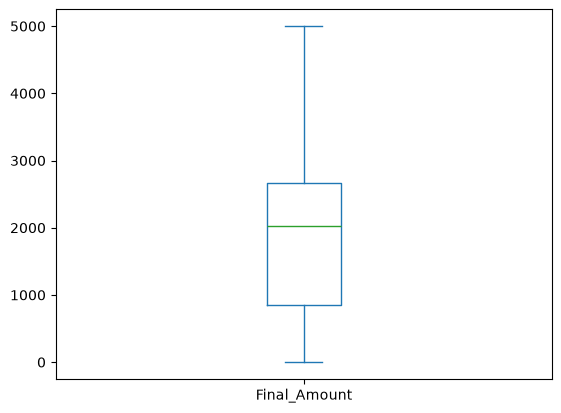

In [87]:
df["Final_Amount"].plot(kind="box")

<Axes: >

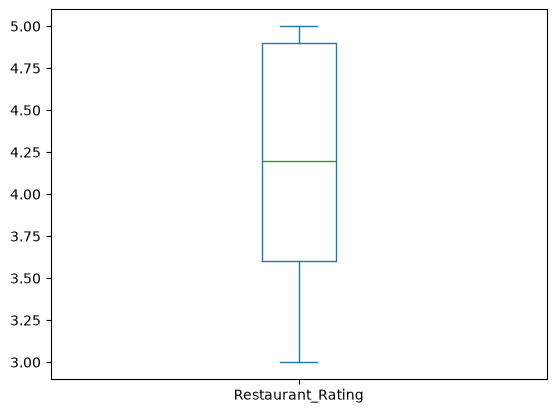

In [88]:
df["Restaurant_Rating"].plot(kind="box")

<Axes: >

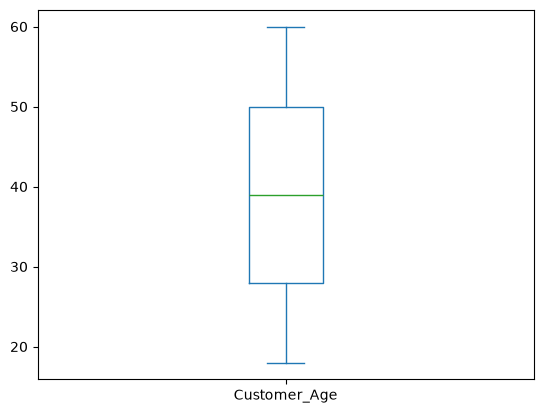

In [89]:
df["Customer_Age"].plot(kind="box")

<Axes: >

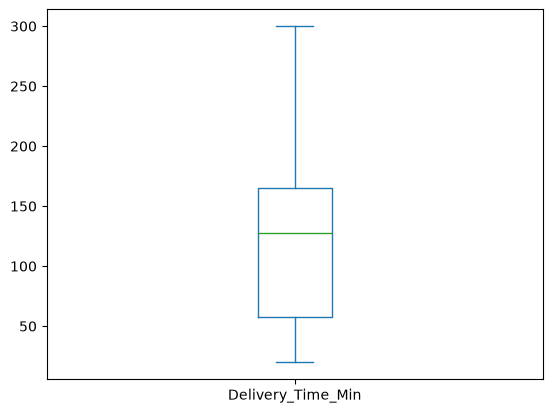

In [90]:
df["Delivery_Time_Min"].plot(kind="box")

<Axes: >

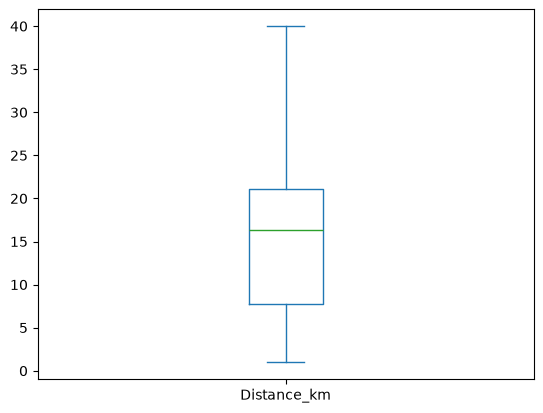

In [91]:
df["Distance_km"].plot(kind="box")

<Axes: >

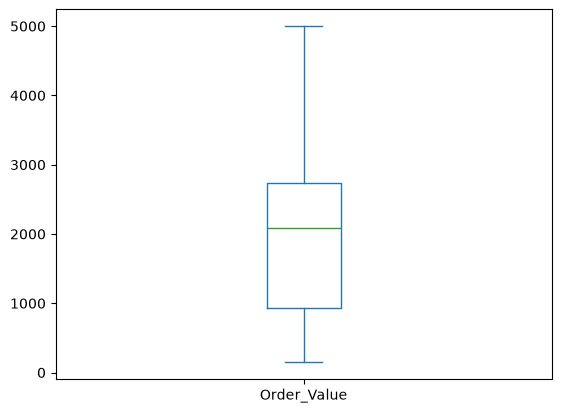

In [92]:
df["Order_Value"].plot(kind="box")

<Axes: >

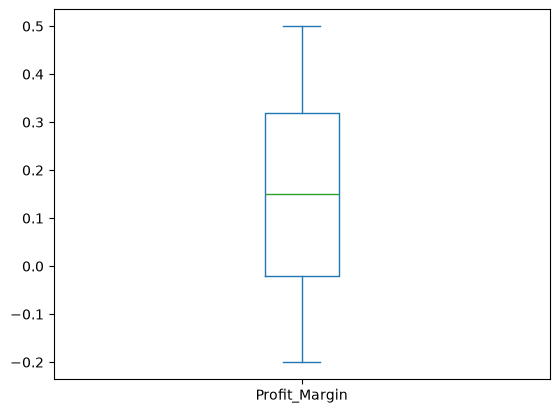

In [93]:
df['Profit_Margin'].plot(kind="box")

In [94]:
df["Delivery_Time_Min"].quantile([0.90, 0.95, 0.99])

0.90    246
0.95    273
0.99    295
Name: Delivery_Time_Min, dtype: Int64

In [95]:
Q1 = df["Delivery_Time_Min"].quantile(0.25)
Q3 = df["Delivery_Time_Min"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Lower Limit:", lower)
print("Upper Limit:", upper)

print("Outliers:",
      ((df["Delivery_Time_Min"] < lower) |
       (df["Delivery_Time_Min"] > upper)).sum())

Lower Limit: -102.5
Upper Limit: 325.5
Outliers: 0


In [96]:
outlier_cols = [
    "Customer_Age",
    "Delivery_Time_Min",
    "Distance_km",
    "Order_Value",
    "Final_Amount"
]

df[outlier_cols].describe()

,Customer_Age,Delivery_Time_Min,Distance_km,Order_Value,Final_Amount
count,100000.0,84964.0,100000.000000,100000.000000,100000.00000
mean,38.99905,127.48005,16.449519,2081.886740,2004.24651
std,12.362767,74.183827,9.997431,1268.589763,1271.89877
min,18.0,20.0,1.000000,150.000000,0.00000
25%,28.0,58.0,7.760000,935.000000,856.00000
50%,39.0,128.0,16.390000,2082.000000,2032.00000
75%,50.0,165.0,21.130000,2743.000000,2663.00000
max,60.0,300.0,40.000000,5000.000000,5000.00000


In [97]:
for col in outlier_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    print("\n", col)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Limit:", lower)
    print("Upper Limit:", upper)


 Customer_Age
Q1: 28.0
Q3: 50.0
IQR: 22.0
Lower Limit: -5.0
Upper Limit: 83.0

 Delivery_Time_Min
Q1: 58
Q3: 165
IQR: 107
Lower Limit: -102.5
Upper Limit: 325.5

 Distance_km
Q1: 7.76
Q3: 21.13
IQR: 13.37
Lower Limit: -12.295
Upper Limit: 41.185

 Order_Value
Q1: 935.0
Q3: 2743.0
IQR: 1808.0
Lower Limit: -1777.0
Upper Limit: 5455.0

 Final_Amount
Q1: 856.0
Q3: 2663.0
IQR: 1807.0
Lower Limit: -1854.5
Upper Limit: 5373.5


## Outlier treatment
- I checked delivery time, order value, final amount, distance and age using box plots, range checks and the IQR method.
- No outliers were found, so no rows were removed or capped. Removing valid orders would only lose information.
- The only capping was for invalid values: restaurant ratings above 5 were capped at 5, and discounts above the order value were capped at the order value.

# CORRELATION ANALYSIS

In [98]:
df.select_dtypes(include='number').columns
df.nunique()       

Order_ID               100000
Customer_ID              8999
Customer_Age               43
Customer_Gender             4
City                        6
Area                        6
Restaurant_ID             900
Restaurant_Name           500
Cuisine_Type                6
Order_Date                365
Delivery_Time_Min         232
Distance_km              3402
Order_Value              4052
Discount_Applied          154
Final_Amount             4475
Payment_Mode                5
Order_Status                2
Cancellation_Reason         5
Delivery_Partner_ID       900
Delivery_Rating             5
Restaurant_Rating          21
Order_Day                   2
Peak_Hour                   3
Profit_Margin              71
Order_Value_Imputed         2
Order_Date_Missing          2
Is_Loss                     2
dtype: int64

In [99]:
df[numeric_cols].columns

Index(['Customer_Age', 'Delivery_Time_Min', 'Distance_km', 'Order_Value',
       'Discount_Applied', 'Final_Amount', 'Delivery_Rating',
       'Restaurant_Rating', 'Profit_Margin', 'Order_Value_Imputed',
       'Order_Date_Missing', 'Is_Loss'],
      dtype='str')

In [100]:
num_cont_col=['Delivery_Time_Min', 'Distance_km', 'Order_Value', 'Discount_Applied', 'Final_Amount', 'Profit_Margin', 'Restaurant_Rating']

In [101]:
num_dis_cols=['Customer_Age', 'Delivery_Rating', 'Order_Month', 'Is_Loss']

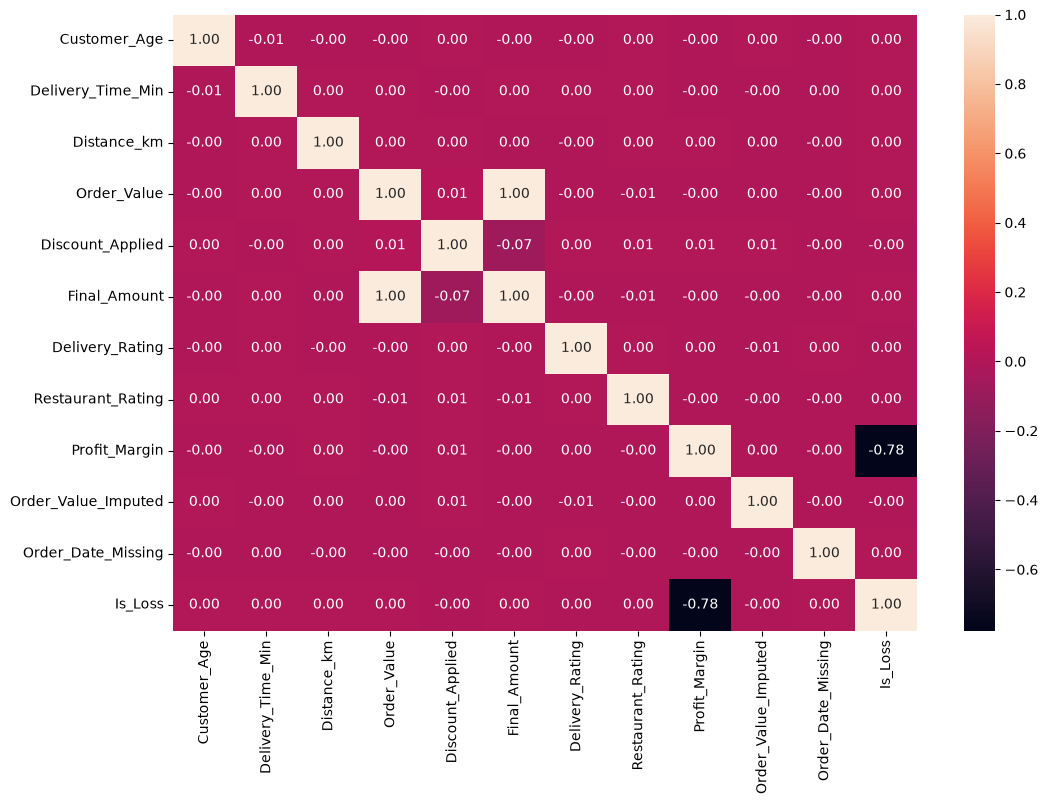

In [102]:
numeric_cols = df.select_dtypes(
    include=["number"]
).columns

corr = df[numeric_cols].corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, fmt=".2f")
plt.show()

 UNIVARIATE

NUMERICAL COLUMNS

In [103]:
df[numeric_cols].columns

Index(['Customer_Age', 'Delivery_Time_Min', 'Distance_km', 'Order_Value',
       'Discount_Applied', 'Final_Amount', 'Delivery_Rating',
       'Restaurant_Rating', 'Profit_Margin', 'Order_Value_Imputed',
       'Order_Date_Missing', 'Is_Loss'],
      dtype='str')

In [104]:
df.groupby("Discount_Applied")["Profit_Margin"].mean()

Discount_Applied
0.0      0.150087
20.0     0.149466
50.0     0.148529
100.0    0.151326
150.0    0.300000
           ...   
296.0    0.276667
297.0    0.296667
298.0    0.115000
299.0    0.450000
300.0    0.152895
Name: Profit_Margin, Length: 154, dtype: float64

In [105]:
df[numeric_cols]['Customer_Age'].describe()

count     100000.0
mean      38.99905
std      12.362767
min           18.0
25%           28.0
50%           39.0
75%           50.0
max           60.0
Name: Customer_Age, dtype: Float64

CATEGORICAL COLUMNS

In [106]:
print(categorical_cols)

['Customer_Gender', 'City', 'Area', 'Cuisine_Type', 'Payment_Mode', 'Order_Status', 'Cancellation_Reason', 'Order_Day', 'Peak_Hour']


In [107]:
categorical_cols = df.select_dtypes(include=['str']).columns

for col in categorical_cols:
    print(f"\nValue counts for {col}:")
    print(df[col].value_counts())



Value counts for Order_ID:
Order_ID
ORD000001    1
ORD000002    1
ORD000003    1
ORD000004    1
ORD000005    1
            ..
ORD099996    1
ORD099997    1
ORD099998    1
ORD099999    1
ORD100000    1
Name: count, Length: 100000, dtype: int64

Value counts for Customer_ID:
Customer_ID
CUST2487    24
CUST4431    23
CUST7657    23
CUST7842    23
CUST9262    23
            ..
CUST8726     1
CUST7120     1
CUST8380     1
CUST5157     1
CUST4958     1
Name: count, Length: 8999, dtype: int64

Value counts for Customer_Gender:
Customer_Gender
Other      25135
Female     25031
Male       24978
Unknown    24856
Name: count, dtype: int64

Value counts for City:
City
Hyderabad    16884
Bangalore    16732
Unknown      16726
Delhi        16695
Mumbai       16493
Chennai      16470
Name: count, dtype: int64

Value counts for Area:
Area
South      16725
Unknown    16685
North      16675
West       16653
East       16643
Central    16619
Name: count, dtype: int64

Value counts for Restaurant_ID:
Rest

EDA- Target- Order_Values

1. DISTRIBUTION OF ORDER VALUES-UNIVARIATE ANALYSIS-

Understand how order values are distributed.

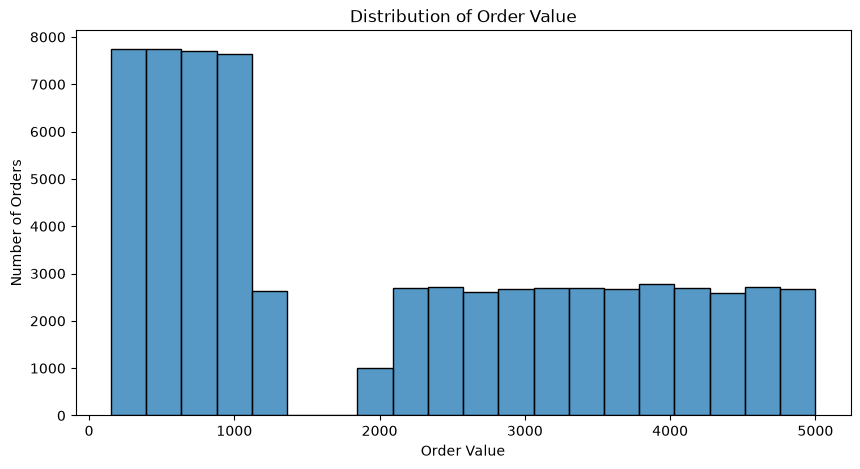

In [108]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df[df["Order_Value_Imputed"] == 0], x="Order_Value", bins=20)

plt.title("Distribution of Order Value")
plt.xlabel("Order Value")
plt.ylabel("Number of Orders")

plt.show()

The distribution of order values was analyzed to understand customer spending behavior and identify the concentration and spread of order values
Order values range from 150 to 5,000. Fewer orders fall between 1,000 and 2,000, and a few high-value orders raise the average above the median.

2. DISTRIBUTION OF DELIVERY TIME -UNIVARIATE-

Understand typical delivery duration and identify unusually long deliveries.

In [109]:
print(len(real_delivery_time.dropna()))

56635


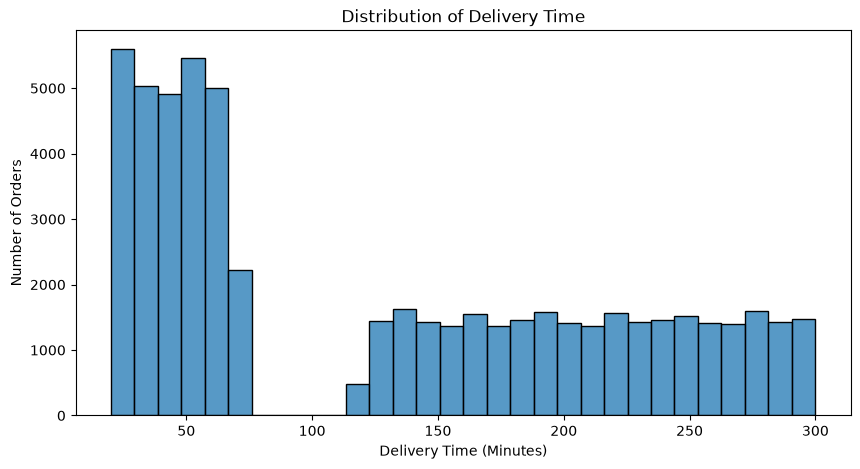

In [110]:
plt.figure(figsize=(10, 5))
sns.histplot(real_delivery_time.dropna(), bins=30)
plt.title("Distribution of Delivery Time")
plt.xlabel("Delivery Time (Minutes)")
plt.ylabel("Number of Orders")
plt.show()

Delivery times form two groups, a fast group (under 70 minutes) and a slow group (over 120 minutes). The average is about 127 minutes.”

3. CITY WISE ORDER ANALYSIS--UNIVARIATE
Identify cities generating the highest number of orders

Categorical Univariate Analysis

In [111]:
df['City'].value_counts()
city_orders = df["City"].value_counts()

print(city_orders)

City
Hyderabad    16884
Bangalore    16732
Unknown      16726
Delhi        16695
Mumbai       16493
Chennai      16470
Name: count, dtype: int64


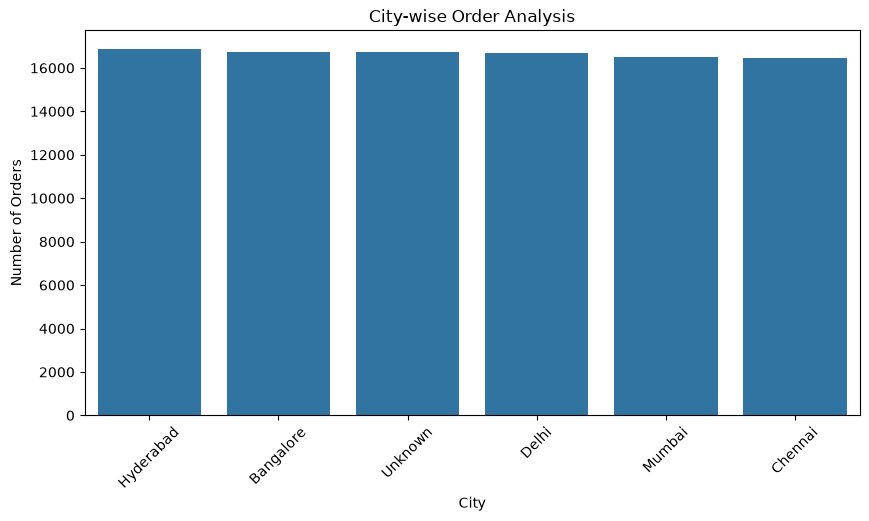

In [112]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="City",
    order=df["City"].value_counts().index
)

plt.title("City-wise Order Analysis")
plt.xlabel("City")
plt.ylabel("Number of Orders")

plt.xticks(rotation=45)

plt.show()

Orders are spread almost equally across all cities (about 16,500 each), so no city clearly dominates.

City-wise order analysis was performed to identify geographical differences in order demand.

4. CUISINE WISE ORDER ANALYSIS-UNIVARIATE 
Identify the most popular cuisine types.

In [113]:
df['Cuisine_Type'].value_counts()

Cuisine_Type
Unknown    16885
Indian     16685
Arabian    16658
Chinese    16651
Mexican    16602
Italian    16519
Name: count, dtype: int64

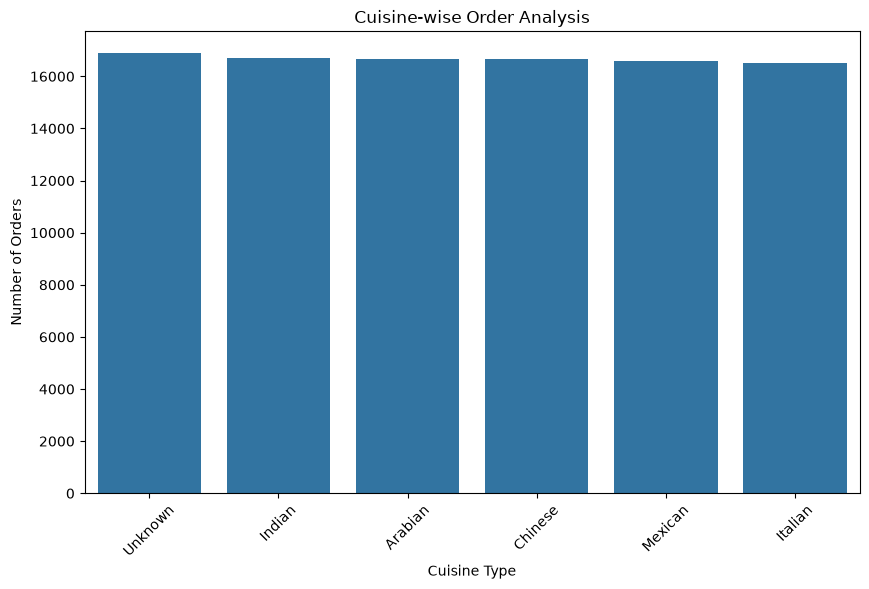

In [114]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="Cuisine_Type",
    order=df["Cuisine_Type"].value_counts().index
)

plt.title("Cuisine-wise Order Analysis")
plt.xlabel("Cuisine Type")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.show()

Cuisine-wise analysis was performed to identify customer preferences and determine which cuisine types generate the highest order demand.
All cuisines have similar order counts, so customer preference is balanced

5. WEEKEND VS WEEKDAY DEMAND -  UNIVARIATE Categorical analysis

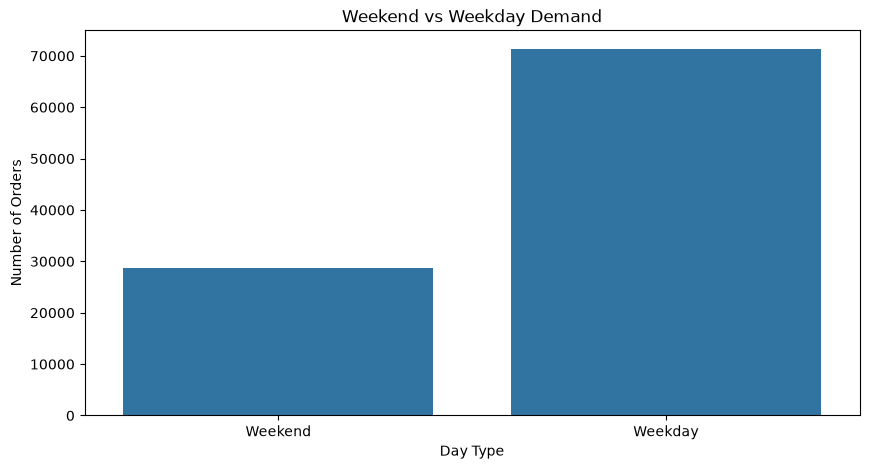

In [115]:
plt.figure(figsize=(10, 5))

sns.countplot(data=df, x="Order_Day")

plt.title("Weekend vs Weekday Demand")
plt.xlabel("Day Type")
plt.ylabel("Number of Orders")
plt.show()

Weekend and weekday order demand was compared to identify differences in customer ordering patterns across day types.
Weekdays have more orders only because there are more weekdays. Per day, demand is the same on weekdays and weekends.

6. DISTANCE VS DELIVERY DELAY- BIVARIATE
Relationship Between Distance and Delivery Time

Both are Numerical continuous

In [116]:
df.loc[real_delivery_time.notna(), ["Distance_km", "Delivery_Time_Min"]].corr()

,Distance_km,Delivery_Time_Min
Distance_km,1.000000,0.005607
Delivery_Time_Min,0.005607,1.000000


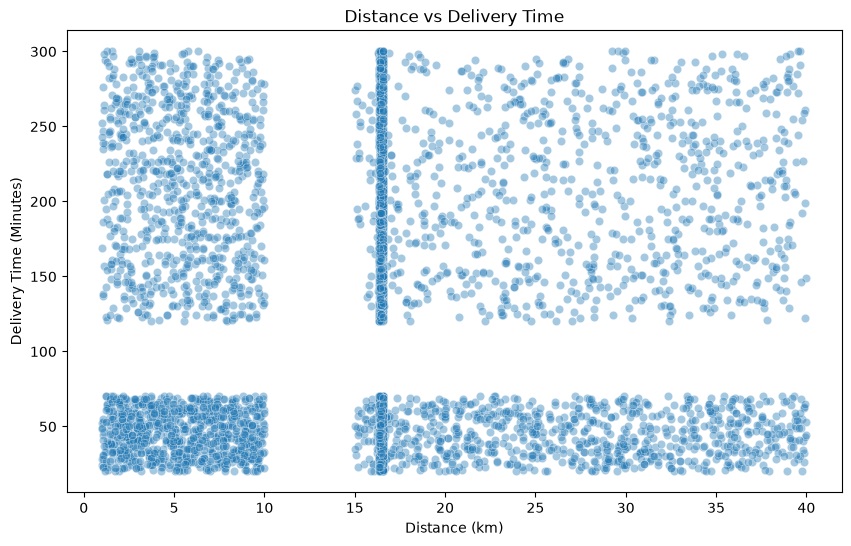

In [117]:
sample_df = df[real_delivery_time.notna()].sample(5000, random_state=42)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=sample_df,
    x="Distance_km",
    y="Delivery_Time_Min",
    alpha=0.4
)

plt.title("Distance vs Delivery Time")
plt.xlabel("Distance (km)")
plt.ylabel("Delivery Time (Minutes)")

plt.show()

Distance has almost no relationship with delivery time (correlation about 0.005), so distance does not explain delays.

7. CANCELLATION REASONS - UNIVARIATE-Categorical


In [118]:
cancelled = df[df["Order_Status"].str.contains("cancel", case=False, na=False)]
reason_counts = cancelled["Cancellation_Reason"].value_counts()

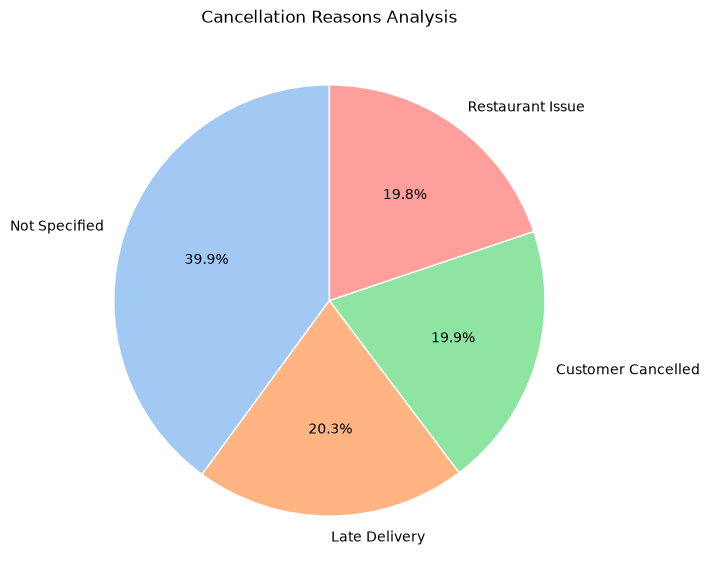

In [119]:
plt.figure(figsize=(7, 7))
plt.pie(reason_counts.values,
        labels=reason_counts.index,
        autopct="%1.1f%%",
        startangle=90,
        colors=sns.color_palette("pastel"),
        wedgeprops={"edgecolor": "white"})
plt.title("Cancellation Reasons Analysis")
plt.show()

Cancellation reason analysis was performed to identify the major factors contributing to cancelled orders and highlight areas for operational improvement

8. CORRELATION ANALSYSIS AMOUNG NUMERIC FEATURES- MULTIVARIATE

In [120]:
corr = df.select_dtypes(include="number").corr()
print(corr)

                     Customer_Age  Delivery_Time_Min  Distance_km  \
Customer_Age             1.000000          -0.010714    -0.002778   
Delivery_Time_Min       -0.010714           1.000000     0.004550   
Distance_km             -0.002778           0.004550     1.000000   
Order_Value             -0.001604           0.000958     0.001030   
Discount_Applied         0.000806          -0.001334     0.003903   
Final_Amount            -0.001665           0.001065     0.000708   
Delivery_Rating         -0.000429           0.002393    -0.000570   
Restaurant_Rating        0.001443           0.002169     0.004025   
Profit_Margin           -0.001039          -0.003178     0.001436   
Order_Value_Imputed      0.002023          -0.002513     0.000140   
Order_Date_Missing      -0.002608           0.000089    -0.001689   
Is_Loss                  0.003566           0.002622     0.001113   

                     Order_Value  Discount_Applied  Final_Amount  \
Customer_Age           -0.001604  

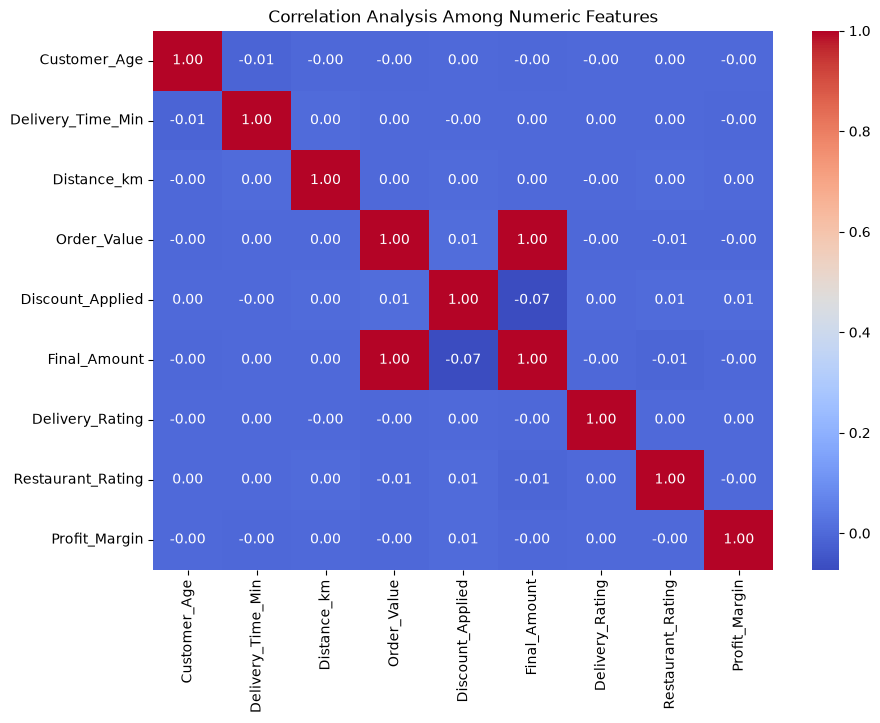

In [121]:
numeric_cols = [
    "Customer_Age",
    "Delivery_Time_Min",
    "Distance_km",
    "Order_Value",
    "Discount_Applied",
    "Final_Amount",
    "Delivery_Rating",
    "Restaurant_Rating",
    "Profit_Margin"
]

corr = df[numeric_cols].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Analysis Among Numeric Features")
plt.show()

# FEATURE ENGINEERING

1. Order Day Type — Weekday / Weekend
Do customers place more orders on weekdays or weekends?

In [122]:
df["Order_Date"].dtype

dtype('<M8[us]')

In [123]:
df["Order_Day_Type"] = np.where(
    df["Order_Date_Missing"] == 0,
    np.where(df["Order_Date"].dt.dayofweek >= 5, "Weekend", "Weekday"),
    df["Order_Day"]
)

In [124]:
df["Order_Day_Type"].value_counts()

Order_Day_Type
Weekday    71370
Weekend    28630
Name: count, dtype: int64

In [125]:
df[["Order_Date", "Order_Day_Type"]].head()

,Order_Date,Order_Day_Type
0,2024-10-20,Weekend
1,2024-08-12,Weekday
2,2024-12-08,Weekend
3,2024-10-08,Weekday
4,2024-02-04,Weekend


2. Peak hour indicator


In [126]:
df["Peak_Hour"].value_counts(dropna=False)

Peak_Hour
Off-Peak    33585
Peak        33453
Unknown     32962
Name: count, dtype: int64

3.Profit margin percentage

In [127]:
df["Profit_Margin_Percentage"] = (
    df["Profit_Margin"] * 100
)

In [128]:
df["Profit_Margin_Percentage"].describe()

count    100000.000000
mean         15.036200
std          20.188757
min         -20.000000
25%          -2.000000
50%          15.000000
75%          32.000000
max          50.000000
Name: Profit_Margin_Percentage, dtype: float64

4. Delivery Performance Category

In [129]:
df["Delivery_Performance"] = pd.cut(
    df["Delivery_Time_Min"], bins=[0, 30, 45, 1000],
    labels=["Fast", "On Time", "Delayed"]
).astype("string").fillna("Unknown")
df.loc[df["Order_Status"].eq("Cancelled"), "Delivery_Performance"] = "Not Applicable"


In [130]:
df["Delivery_Performance"].value_counts()

Delivery_Performance
Delayed           70461
Not Applicable    15036
On Time            8357
Fast               6146
Name: count, dtype: Int64

In [131]:
perf = pd.cut(real_delivery_time.dropna(), bins=[0, 30, 45, 1000], labels=["Fast", "On Time", "Delayed"])
print((perf.value_counts(normalize=True) * 100).round(1))

Delivery_Time_Min
Delayed    74.4
On Time    14.8
Fast       10.9
Name: proportion, dtype: float64


5.Customer age groups

In [132]:
df["Age_Group"] = pd.cut(df["Customer_Age"],bins=[0, 25, 35, 50, 100],
    labels=["Under 25", "25-35", "36-50", "Above 50"])

In [133]:
df["Age_Group"].value_counts()

Age_Group
36-50       35257
25-35       23321
Above 50    22967
Under 25    18455
Name: count, dtype: int64

In [134]:
df[[
    "Order_Day_Type",
    "Peak_Hour",
    "Profit_Margin_Percentage",
    "Delivery_Performance",
    "Age_Group"
    ]].head()

,Order_Day_Type,Peak_Hour,Profit_Margin_Percentage,Delivery_Performance,Age_Group
0,Weekend,Peak,13.0,Delayed,Under 25
1,Weekday,Peak,48.0,Fast,25-35
2,Weekend,Peak,8.0,Delayed,Above 50
3,Weekday,Unknown,4.0,Not Applicable,36-50
4,Weekend,Off-Peak,12.0,Delayed,Above 50


In [135]:
df.isnull().sum()

Order_ID                        0
Customer_ID                     0
Customer_Age                    0
Customer_Gender                 0
City                            0
Area                            0
Restaurant_ID                   0
Restaurant_Name                 0
Cuisine_Type                    0
Order_Date                      0
Delivery_Time_Min           15036
Distance_km                     0
Order_Value                     0
Discount_Applied                0
Final_Amount                    0
Payment_Mode                    0
Order_Status                    0
Cancellation_Reason             0
Delivery_Partner_ID             0
Delivery_Rating             15036
Restaurant_Rating               0
Order_Day                       0
Peak_Hour                       0
Profit_Margin                   0
Order_Value_Imputed             0
Order_Date_Missing              0
Is_Loss                         0
Order_Day_Type                  0
Profit_Margin_Percentage        0
Delivery_Perfo

In [136]:
df_export = df.copy()
df_export["Delivery_Time_Min"] = df_export["Delivery_Time_Min"].fillna(0).round().astype("Int64")
df_export["Delivery_Rating"] = df_export["Delivery_Rating"].fillna(0).round().astype("Int64")

df_export.to_csv("food_delivery.csv", index=False)
print(f"Saved cleaned data to food_delivery.csv")
print("Exported shape:", df_export.shape)
print("Remaining null counts:")
print(df_export.isnull().sum()[lambda counts: counts > 0])


Saved cleaned data to food_delivery.csv
Exported shape: (100000, 31)
Remaining null counts:
Series([], dtype: int64)


In [137]:
from sqlalchemy import create_engine

username = "postgres"
password = "Mls1102"
host = "localhost"
port = "5432"
database = "food_delivery"

DATABASE_URL = (
f"postgresql+psycopg2://{username}:{password}@{host}:{port}/{database}"
)

engine = create_engine(DATABASE_URL)

with engine.connect() as connection:
    print("PostgreSQL connected successfully!")

PostgreSQL connected successfully!


In [138]:
df.to_sql("food_delivery",engine,if_exists="replace", index=False)

1000

In [139]:
result = pd.read_sql(
    "SELECT * FROM food_delivery LIMIT 10", engine)

result

,Order_ID,Customer_ID,Customer_Age,Customer_Gender,City,Area,Restaurant_ID,Restaurant_Name,Cuisine_Type,Order_Date,...,Order_Day,Peak_Hour,Profit_Margin,Order_Value_Imputed,Order_Date_Missing,Is_Loss,Order_Day_Type,Profit_Margin_Percentage,Delivery_Performance,Age_Group
0,ORD000001,CUST6948,19,Male,Unknown,Central,RES936,Restaurant_29,Chinese,2024-10-20,...,Weekend,Peak,0.13,1,0,0,Weekend,13.0,Delayed,Under 25
1,ORD000002,CUST6515,30,Female,Chennai,North,RES689,Restaurant_419,Chinese,2024-08-12,...,Weekday,Peak,0.48,0,0,0,Weekday,48.0,Fast,25-35
2,ORD000003,CUST1765,58,Male,Delhi,Unknown,RES723,Restaurant_244,Arabian,2024-12-08,...,Weekend,Peak,0.08,0,0,0,Weekend,8.0,Delayed,Above 50
3,ORD000004,CUST2744,41,Male,Mumbai,Central,RES951,Restaurant_178,Chinese,2024-10-08,...,Weekday,Unknown,0.04,1,0,0,Weekday,4.0,Not Applicable,36-50
4,ORD000005,CUST4389,57,Female,Chennai,South,RES419,Restaurant_262,Chinese,2024-02-04,...,Weekend,Off-Peak,0.12,0,0,0,Weekend,12.0,Delayed,Above 50
5,ORD000006,CUST3161,37,Other,Chennai,East,RES810,Restaurant_153,Mexican,2024-07-09,...,Weekday,Peak,0.24,1,0,0,Weekday,24.0,Delayed,36-50
6,ORD000007,CUST2307,40,Other,Delhi,Unknown,RES333,Restaurant_302,Chinese,2024-02-14,...,Weekday,Unknown,0.02,1,0,0,Weekday,2.0,Delayed,36-50
7,ORD000008,CUST5865,50,Male,Unknown,North,RES696,Restaurant_41,Chinese,2024-05-26,...,Weekend,Unknown,0.18,0,0,0,Weekend,18.0,Delayed,36-50
8,ORD000009,CUST4356,46,Other,Delhi,Central,RES780,Restaurant_155,Italian,2024-09-07,...,Weekend,Peak,0.08,0,0,0,Weekend,8.0,Delayed,36-50
9,ORD000010,CUST2404,46,Female,Unknown,South,RES155,Restaurant_368,Chinese,2024-01-22,...,Weekday,Peak,0.03,0,0,0,Weekday,3.0,Delayed,36-50
